In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

csv = "walkTest/001_dt.csv"
ideal = 1 / 120                      # 0.008333 s

df = pd.read_csv(csv).dropna(subset=["dt_s"])
df["err_ms"]   = (df.dt_s - ideal) * 1e3        # absolute error per frame
df["err_pct"]  = (df.dt_s / ideal - 1) * 100    # relative error per frame
df["drift_ms"] = df.err_ms.cumsum()             # accumulated time vs. ideal 120 fps clock

print(f"frames: {len(df)+1}   mean dt: {df.dt_s.mean()*1e3:.4f} ms   "
      f"mean fps: {1/df.dt_s.mean():.3f}")
print(f"min/max dt: {df.dt_ms.min():.3f} / {df.dt_ms.max():.3f} ms   "
      f"std: {df.dt_ms.std():.4f} ms")
print(f"total drift vs ideal: {df.drift_ms.iloc[-1]:.2f} ms over {df.pts_s.iloc[-1]:.2f} s")

frames: 3126   mean dt: 8.3379 ms   mean fps: 119.935
min/max dt: 7.916 / 8.750 ms   std: 0.0492 ms
total drift vs ideal: 14.17 ms over 26.06 s


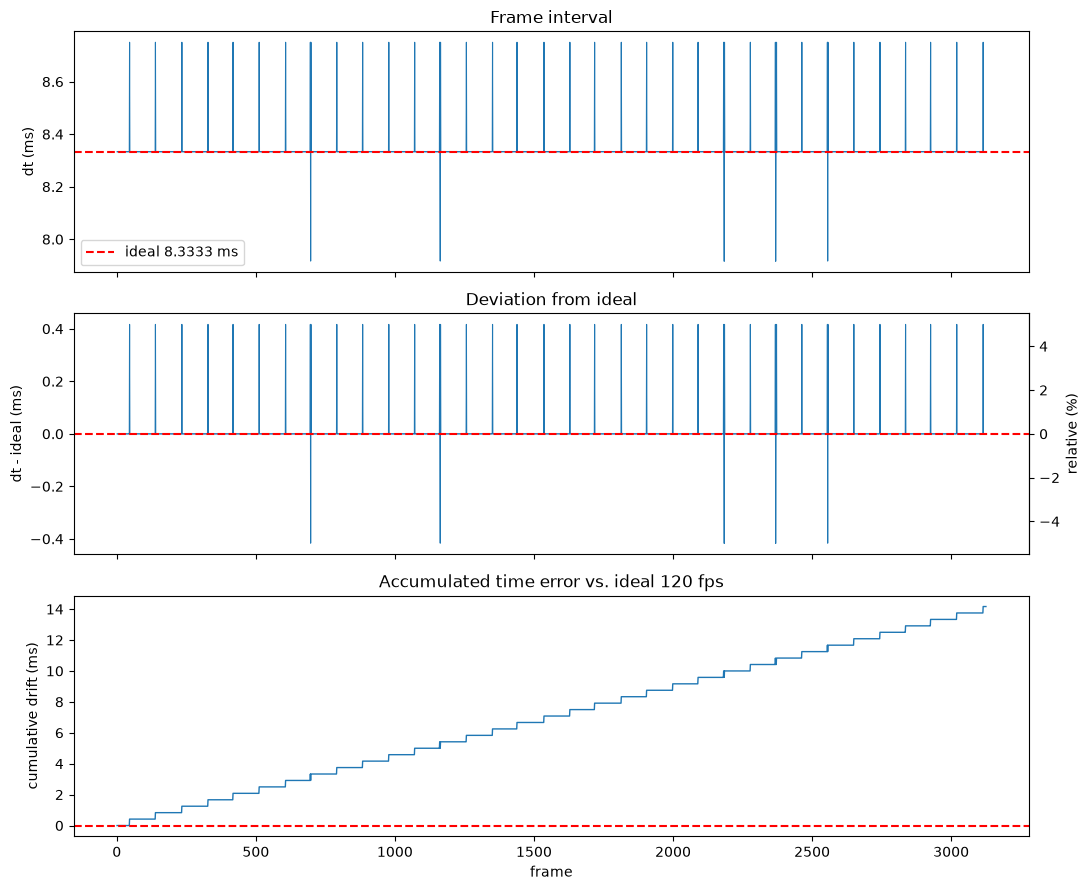

In [2]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

# 1) raw dt with the ideal line
ax[0].plot(df.frame, df.dt_ms, lw=0.8)
ax[0].axhline(ideal * 1e3, color="r", ls="--", label=f"ideal {ideal*1e3:.4f} ms")
ax[0].set_ylabel("dt (ms)"); ax[0].set_title("Frame interval"); ax[0].legend()

# 2) deviation from ideal: absolute (left) and relative (right)
ax[1].plot(df.frame, df.err_ms, lw=0.8)
ax[1].axhline(0, color="r", ls="--")
ax[1].set_ylabel("dt - ideal (ms)"); ax[1].set_title("Deviation from ideal")
sec = ax[1].secondary_yaxis("right",
        functions=(lambda ms: ms / (ideal * 1e3) * 100,
                   lambda pct: pct * (ideal * 1e3) / 100))
sec.set_ylabel("relative (%)")

# 3) accumulated drift
ax[2].plot(df.frame, df.drift_ms, lw=1)
ax[2].axhline(0, color="r", ls="--")
ax[2].set_ylabel("cumulative drift (ms)"); ax[2].set_xlabel("frame")
ax[2].set_title("Accumulated time error vs. ideal 120 fps")

plt.tight_layout(); plt.show()

 ticks  dt_ms  count   pct
    19  7.917      5  0.16
    20  8.333   3081 98.59
    21  8.750     39  1.25


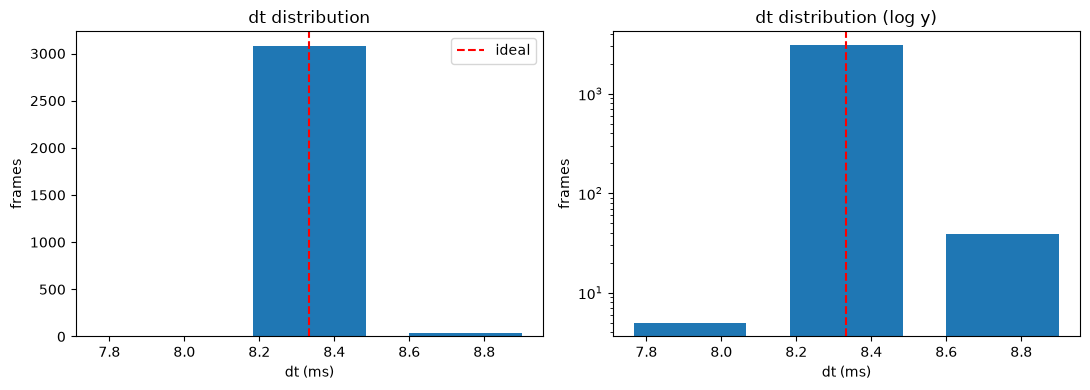

In [3]:
ticks  = (df.dt_s * 2400).round().astype(int)          # dt in units of 1/2400 s
counts = ticks.value_counts().sort_index()

print(pd.DataFrame({
    "ticks": counts.index,
    "dt_ms": (counts.index / 2400 * 1e3).round(3),
    "count": counts.values,
    "pct":   (counts.values / len(df) * 100).round(2),
}).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, log in zip(ax, (False, True)):
    a.bar(counts.index / 2400 * 1e3, counts.values, width=0.3)
    a.axvline(ideal * 1e3, color="r", ls="--", label="ideal")
    a.set_xlabel("dt (ms)"); a.set_ylabel("frames")
    a.set_title("dt distribution" + (" (log y)" if log else ""))
    if log: a.set_yscale("log")
ax[0].legend()
plt.tight_layout(); plt.show()

=== walkTest/001_dt.csv: 3126 frames, 26.06 s ===

[grid]    max distance from the 1/2400 s grid: 0.0016 ticks (OK)
[drops]   min/max dt: 19 / 21 ticks (7.917 / 8.750 ms); gaps >= 1.5x nominal: 0 -> no dropped frames
[jitter]  std: 0.0492 ms = 0.59% of a frame interval
          exactly nominal  :  3081 frames (98.59%)
          -1 tick          :     5 frames ( 0.16%)
          +1 tick          :    39 frames ( 1.25%)
          |dev| >= 2 ticks :     0 frames ( 0.00%)
[rate]    mean dt 8.3379 ms vs ideal 8.3333 ms -> 119.935 fps, -0.0544% vs nominal (slower than 120)
[drift]   total +14.17 ms = +34.0 ticks = +1.70 frame intervals over 26.06 s
          net ticks from deviations: +34  (+1 frames: 39, -1 frames: 5, surplus: +34)
[shape]   linear fit: slope 4.485 us/frame, R^2 = 0.9991, implied rate 119.935 fps, max residual 0.52 ticks
          -> smooth ramp (systematic rate offset)
          net ticks per decile of the clip: [3, 4, 3, 3, 4, 3, 4, 3, 3, 4]
          +1 events: mean spa

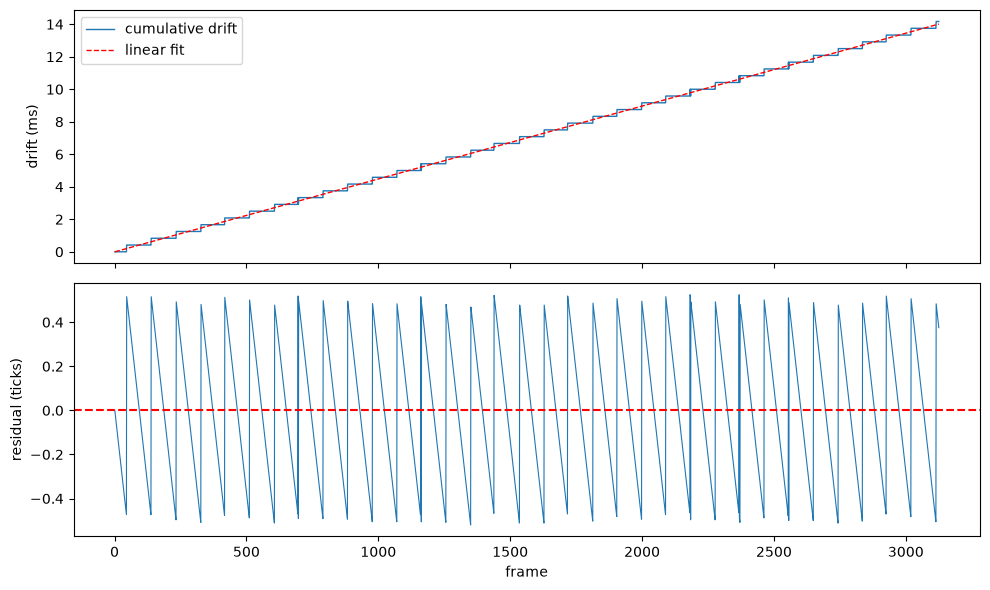

In [5]:
import glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt

CSV     = "walkTest/001_dt.csv"
NOMINAL = 120      # fps
TICK_HZ = 2400     # container timescale (tbn in ffprobe)

ideal   = 1 / NOMINAL
nom_tk  = TICK_HZ // NOMINAL          # 20 ticks
tick_ms = 1e3 / TICK_HZ               # 0.4167 ms

d   = pd.read_csv(CSV).dropna(subset=["dt_s"]).reset_index(drop=True)
dt  = d.dt_s.to_numpy()
n   = len(dt)
tk  = np.round(dt * TICK_HZ).astype(int)     # dt in ticks
dev = tk - nom_tk                            # deviation from nominal, in ticks
fps = 1 / dt.mean()
drift_ms = np.cumsum(dt - ideal) * 1e3

print(f"=== {CSV}: {n+1} frames, {dt.sum():.2f} s ===\n")

# 0) is the 1/2400 s grid assumption valid?
off_grid = np.abs(dt * TICK_HZ - tk).max()
print(f"[grid]    max distance from the 1/{TICK_HZ} s grid: {off_grid:.4f} ticks "
      f"({'OK' if off_grid < 0.01 else 'grid assumption is WRONG, check TICK_HZ'})")

# 1) dropped frames
big = tk >= 1.5 * nom_tk
print(f"[drops]   min/max dt: {tk.min()} / {tk.max()} ticks "
      f"({tk.min()*tick_ms:.3f} / {tk.max()*tick_ms:.3f} ms); "
      f"gaps >= 1.5x nominal: {big.sum()} "
      f"-> {'no dropped frames' if big.sum() == 0 else 'DROPPED FRAMES at ' + str(np.where(big)[0][:10])}")

# 2) jitter
print(f"[jitter]  std: {dt.std(ddof=1)*1e3:.4f} ms = {dt.std(ddof=1)/ideal*100:.2f}% of a frame interval")
for lbl, m in (("exactly nominal", dev == 0), ("-1 tick", dev == -1), ("+1 tick", dev == 1),
               ("|dev| >= 2 ticks", np.abs(dev) >= 2)):
    print(f"          {lbl:<17}: {m.sum():5d} frames ({m.mean()*100:5.2f}%)")

# 3) rate vs nominal
print(f"[rate]    mean dt {dt.mean()*1e3:.4f} ms vs ideal {ideal*1e3:.4f} ms -> {fps:.3f} fps, "
      f"{(fps/NOMINAL-1)*100:+.4f}% vs nominal "
      f"({'slower' if fps < NOMINAL else 'faster'} than {NOMINAL})")

# 4) drift
tot = drift_ms[-1]
print(f"[drift]   total {tot:+.2f} ms = {tot/tick_ms:+.1f} ticks = {tot/1e3/ideal:+.2f} frame intervals "
      f"over {dt.sum():.2f} s")
print(f"          net ticks from deviations: {dev.sum():+d}  "
      f"(+1 frames: {(dev>0).sum()}, -1 frames: {(dev<0).sum()}, surplus: {(dev>0).sum()-(dev<0).sum():+d})")

# ramp or hiccups?
x = np.arange(1, n + 1)
slope, icpt = np.polyfit(x, drift_ms, 1)
fit   = slope * x + icpt
resid = drift_ms - fit
r2    = 1 - resid.var() / drift_ms.var()
fps_fit = 1 / (ideal + slope / 1e3)
max_res_tk = np.abs(resid).max() / tick_ms
print(f"[shape]   linear fit: slope {slope*1e3:.3f} us/frame, R^2 = {r2:.4f}, "
      f"implied rate {fps_fit:.3f} fps, max residual {max_res_tk:.2f} ticks")
print(f"          -> {'smooth ramp (systematic rate offset)' if max_res_tk <= 1.5 else 'localized steps/hiccups on top of the ramp'}")
print("          net ticks per decile of the clip:",
      [int(c.sum()) for c in np.array_split(dev, 10)])
if (dev != 0).any():
    ev = np.where(dev > 0)[0]
    if len(ev) > 1:
        print(f"          +1 events: mean spacing {np.diff(ev).mean():.1f} frames, "
              f"std {np.diff(ev).std():.1f}")

# 5) consistency across clips (every *_dt.csv in this folder)
rows = []
for f in sorted(glob.glob("*_dt.csv")):
    x_ = pd.read_csv(f).dropna(subset=["dt_s"]).dt_s
    rows.append((f, len(x_) + 1, 1 / x_.mean(), (1 / x_.mean() / NOMINAL - 1) * 100))
tab = pd.DataFrame(rows, columns=["file", "frames", "mean_fps", "offset_pct"])
print("\n[clips]"); print(tab.round(4).to_string(index=False))
if len(tab) > 1:
    print(f"          spread across clips: std {tab.mean_fps.std():.4f} fps, "
          f"range {tab.mean_fps.min():.3f} to {tab.mean_fps.max():.3f}")
else:
    print("          only one clip so far, so nothing to compare yet")

# 6) practical effect of using nominal 120
err_ms = abs(fps / NOMINAL - 1) * 1e3          # per 1 s of real time
print(f"\n[impact]  using {NOMINAL} instead of {fps:.3f}: {err_ms:.3f} ms error per second of event "
      f"({err_ms/(ideal*1e3)*100:.1f}% of one frame interval)")
print(f"          measured rate to pass to norm120.sh: {fps:.3f}")

# plot: drift with fit, and residual
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(x, drift_ms, lw=1, label="cumulative drift")
ax[0].plot(x, fit, "r--", lw=1, label="linear fit")
ax[0].set_ylabel("drift (ms)"); ax[0].legend()
ax[1].plot(x, resid / tick_ms, lw=0.8)
ax[1].axhline(0, color="r", ls="--")
ax[1].set_ylabel("residual (ticks)"); ax[1].set_xlabel("frame")
plt.tight_layout(); plt.show()